In [1]:
from catboost import CatBoostClassifier
from catboost import Pool
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
import catboost

In [3]:
df = pd.read_csv("Data/data_kern_ratios_06_10.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3028 entries, 0 to 3027
Data columns (total 54 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Mg                        3028 non-null   float64
 1   Al                        3028 non-null   float64
 2   Si                        3028 non-null   float64
 3   P                         3028 non-null   float64
 4   S                         3028 non-null   float64
 5   K                         3028 non-null   float64
 6   Ca                        3028 non-null   float64
 7   Ti                        3028 non-null   float64
 8   Mn                        3028 non-null   float64
 9   Fe                        3028 non-null   float64
 10  Ni                        3028 non-null   float64
 11  Cu                        3028 non-null   float64
 12  Zn                        3028 non-null   float64
 13  Se                        3028 non-null   float64
 14  Rb      

In [5]:
df['Strat'].value_counts().sort_index()

Strat
0     448
1     156
2     182
3     267
4     233
5     133
6     131
7     194
8     365
9     469
10    267
11    183
Name: count, dtype: int64

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по относительным параметрам на основе элементов и соотношений на новом датасете 05.10 с новой разметкой**

In [6]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

**Расчет скользящих градиентов Δxi = xi - xi-1 по каждой скважине (сортировка по Depth)**

In [7]:
# Сортировка df по скважине и глубине
df_sorted = df.sort_values(['Well', 'Depth']).reset_index(drop=True)

# Для каждого признака разность с предыдущей пробой в той же скважине
gradient_features = []
for col in features:
    grad_col = f'dΔ_{col}'
    df_sorted[grad_col] = df_sorted.groupby('Well')[col].diff()
    gradient_features.append(grad_col)

# Исходный порядок
df = df_sorted

print(f"Добавлено градиентных признаков: {len(gradient_features)}")

Добавлено градиентных признаков: 49


In [8]:
print(df.columns.tolist())

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_

In [9]:
features = ['dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 
            'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 
            'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 
            'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 
            'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 
            'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Fe/(Mn+Fe)', 'dΔ_(Al+K+Ti)/Si', 
            'dΔ_(Al+K+Ti)/S', 'dΔ_(Ti+Rb+Zr)/S', 'dΔ_S/Ti', 'dΔ_Ni/Al', 'dΔ_Zn/Al', 'dΔ_Se/Si', 
            'dΔ_(Ca+Mg)/Al', 'dΔ_Se/Ti', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9946
F1 macro (val):   0.4796
Gap (train-val):  0.5149

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.8218    0.6587    0.7313       126
           1     0.5085    0.5882    0.5455        51
           2     0.3429    0.2609    0.2963        46
           3     0.5056    0.6250    0.5590        72
           4     0.3514    0.5778    0.4370        45
           5     0.0769    0.1667    0.1053         6
           6     0.4815    0.6190    0.5417        21
           7     0.5500    0.1964    0.2895        56
           8     0.3289    0.5102    0.4000        49
           9     0.7105    0.6279    0.6667        86
          10     0.7273    0.4923    0.5872        65
          11     0.5152    0.7083    0.5965        24

    accuracy                    

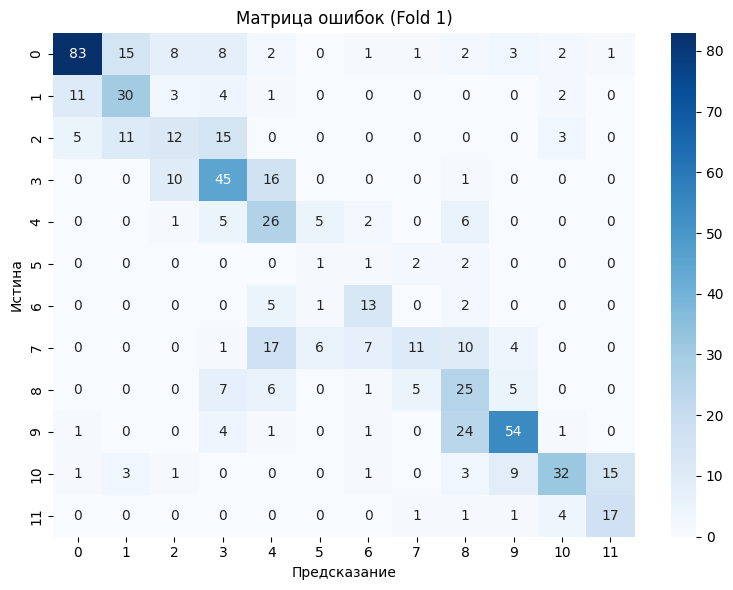

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9959
F1 macro (val):   0.6059
Gap (train-val):  0.3900

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9174    0.8929    0.9050       112
           1     0.3200    0.5714    0.4103        14
           2     0.7143    0.5435    0.6173        46
           3     0.7778    0.7273    0.7517        77
           4     0.6494    0.7353    0.6897        68
           5     0.5263    0.2222    0.3125        45
           6     0.4194    0.4815    0.4483        27
           7     0.3333    0.3871    0.3582        31
           8     0.5843    0.6118    0.5977        85
           9     0.7436    0.7838    0.7632       111
          10     0.5909    0.5909    0.5909        22
          11     0.7308    0.9500    0.8261        20

    accuracy                    

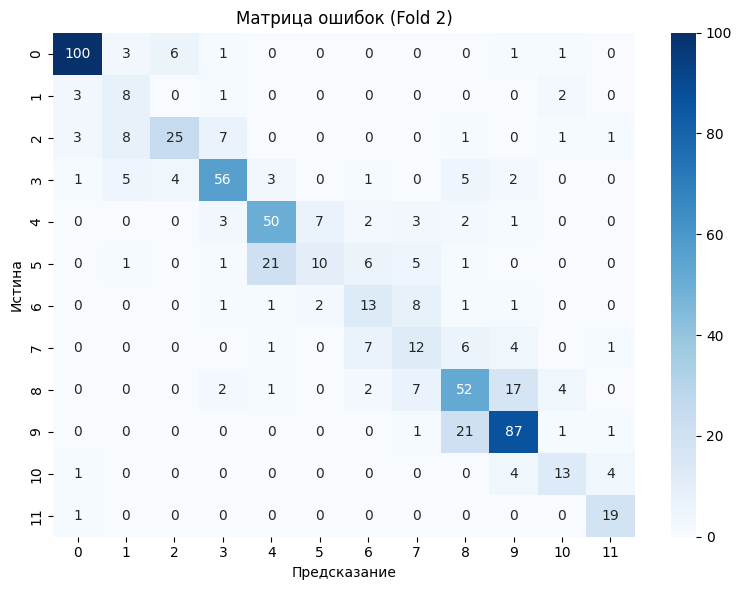

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9957
F1 macro (val):   0.5689
Gap (train-val):  0.4268

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.8561    0.9520    0.9015       125
           1     0.6000    0.4167    0.4918        36
           2     0.6154    0.5000    0.5517        32
           3     0.5349    0.7667    0.6301        30
           4     0.5789    0.6111    0.5946        36
           5     0.4615    0.1667    0.2449        36
           6     0.4545    0.3030    0.3636        33
           7     0.4000    0.3000    0.3429        40
           8     0.5316    0.4773    0.5030        88
           9     0.5614    0.8205    0.6667        78
          10     0.7442    0.7111    0.7273        45
          11     0.7037    0.9500    0.8085        20

    accuracy                    

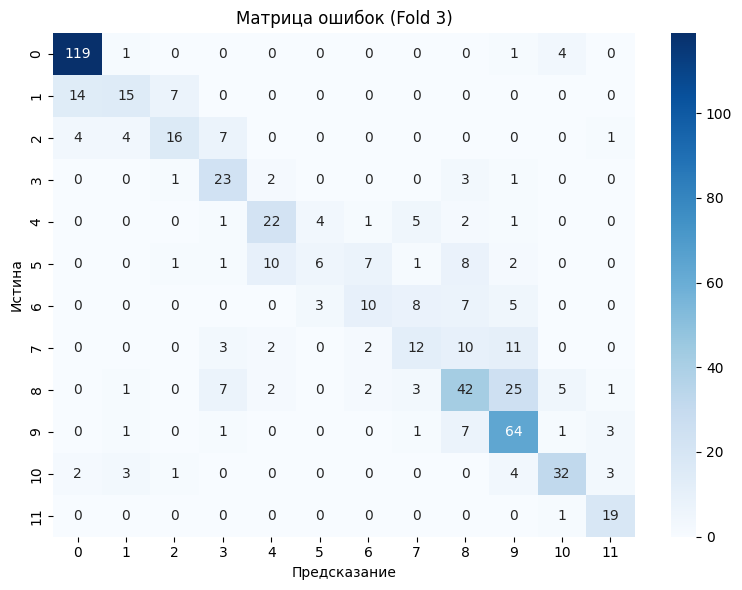

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9926
F1 macro (val):   0.5302
Gap (train-val):  0.4624

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.7403    0.9828    0.8444        58
           1     0.5238    0.2821    0.3667        39
           2     0.3846    0.4286    0.4054        35
           3     0.6000    0.6346    0.6168        52
           4     0.6522    0.5357    0.5882        56
           5     0.2941    0.2083    0.2439        24
           6     0.5455    0.4286    0.4800        28
           7     0.3478    0.1818    0.2388        44
           8     0.3036    0.2698    0.2857        63
           9     0.5514    0.8082    0.6556        73
          10     0.7463    0.8929    0.8130        56
          11     0.8485    0.8000    0.8235        35

    accuracy                    

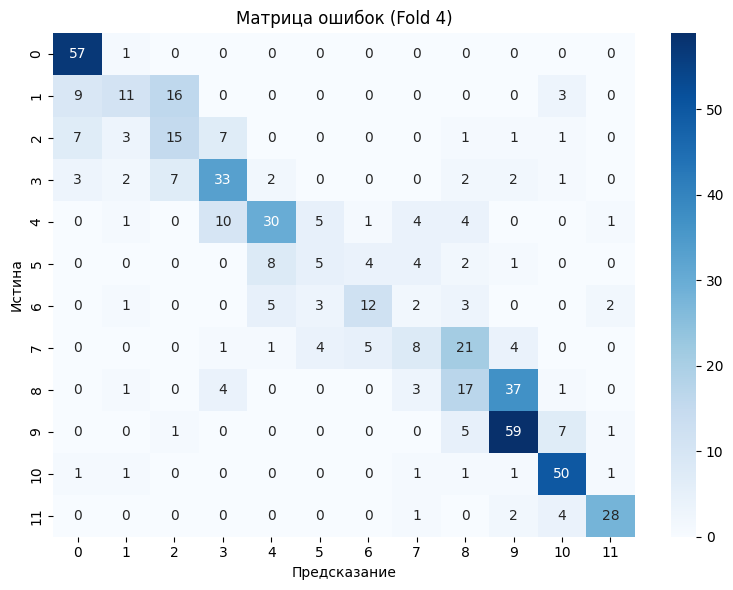

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9931
F1 macro (val):   0.4535
Gap (train-val):  0.5396

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.3086    0.9259    0.4630        27
           1     0.7000    0.4375    0.5385        16
           2     0.6471    0.4783    0.5500        23
           3     0.5854    0.6667    0.6234        36
           4     0.4390    0.6429    0.5217        28
           5     0.0556    0.0455    0.0500        22
           6     0.5000    0.3182    0.3889        22
           7     0.2143    0.2609    0.2353        23
           8     0.4828    0.5250    0.5030        80
           9     0.5600    0.5785    0.5691       121
          10     0.6267    0.5949    0.6104        79
          11     0.8750    0.2500    0.3889        84

    accuracy                    

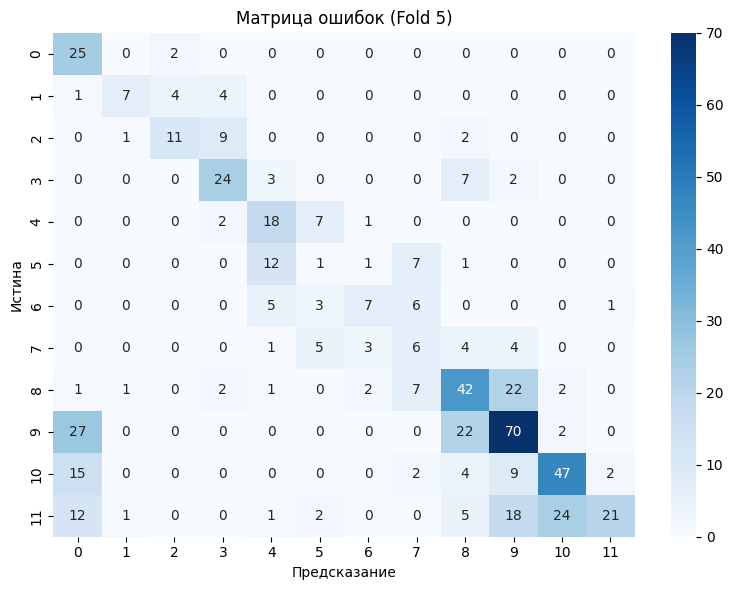

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4796
  Fold 2: F1_macro = 0.6059
  Fold 3: F1_macro = 0.5689
  Fold 4: F1_macro = 0.5302
  Fold 5: F1_macro = 0.4535

  Средний F1 macro: 0.5276 ± 0.0559

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.7574    0.8571    0.8042       448
           1     0.5071    0.4551    0.4797       156
           2     0.5197    0.4341    0.4731       182
           3     0.6033    0.6779    0.6384       267
           4     0.5290    0.6266    0.5737       233
           5     0.2875    0.1729    0.2160       133
           6     0.4741    0.4198    0.4453       131
           7     0.3577    0.2526    0.2961       194
           8     0.4599    0.4877    0.4734       365
           9     0.6197    0.7122    0.6627       469
          10     0.6932    0.6517    0.6718       267
          11     0.7273    0.5683    0.6380       183

    accuracy                         0.5872      

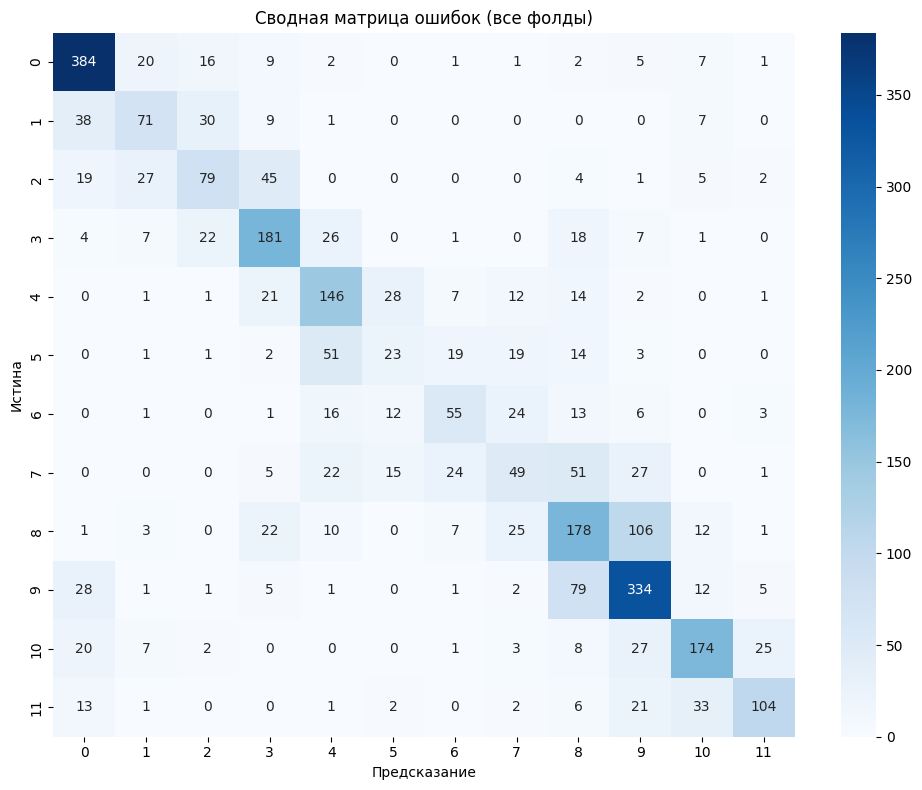

/tmp/ipykernel_405508/1167522210.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

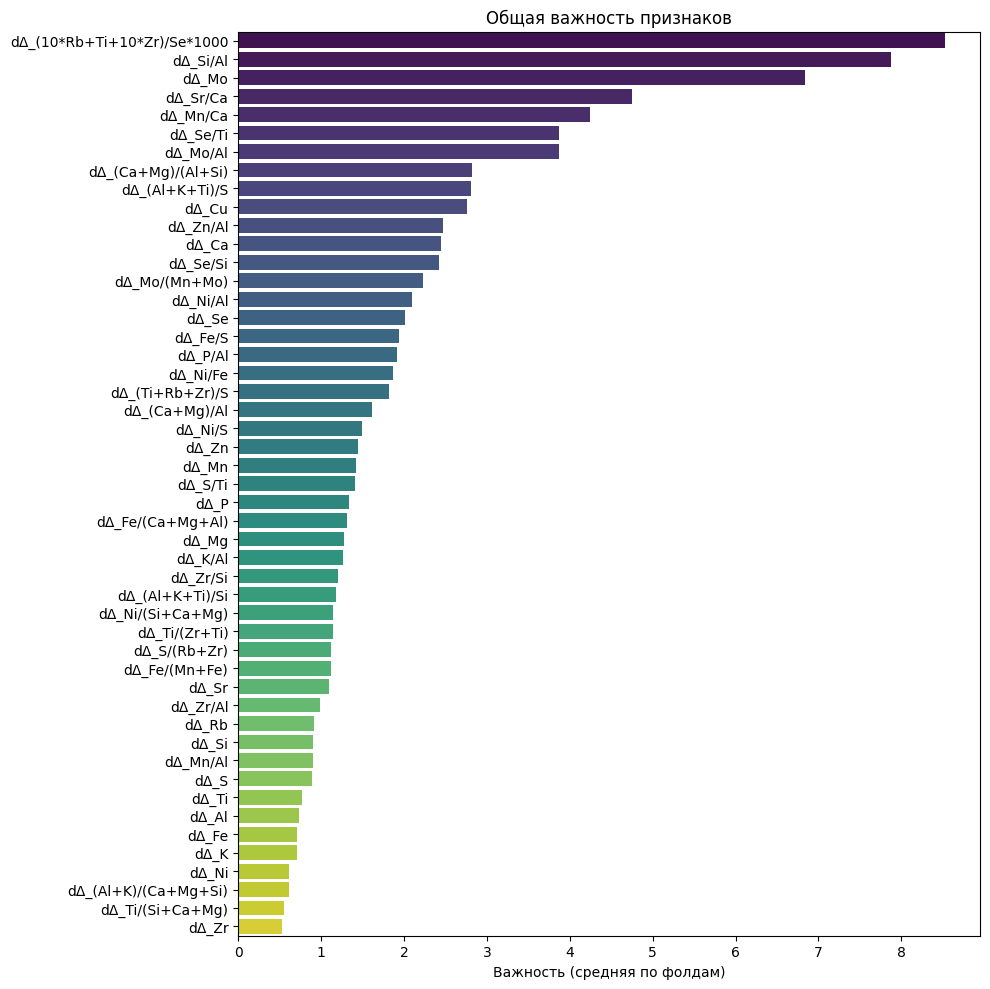

In [10]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Рассчет скользящих z-score с окном k=5, по каждой скважине отдельно**

In [11]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

In [12]:
# z = (x - rolling_mean) / rolling_std

k = 5

# Сортируем по скважине и глубине
df_sorted = df.sort_values(['Well', 'Depth']).reset_index(drop=True)

zscore_features = []
for col in features:
    z_col = f'z5_{col}'
    rolling = df_sorted.groupby('Well')[col].rolling(window=k, center=True, min_periods=3)
    df_sorted[z_col] = (df_sorted[col] - rolling.mean().reset_index(level=0, drop=True)) / \
                       rolling.std().reset_index(level=0, drop=True)
    zscore_features.append(z_col)

# Возвращаем исходный порядок
df = df_sorted.sort_values('index' if 'index' in df_sorted.columns else df_sorted.columns[0]).reset_index(drop=True)

print(f"Добавлено z-score признаков: {len(zscore_features)}")
print(f"Примеры: {zscore_features[:5]}")


Добавлено z-score признаков: 49
Примеры: ['z5_Mg', 'z5_Al', 'z5_Si', 'z5_P', 'z5_S']


In [13]:
print(df.columns.tolist())

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_

In [14]:
features = ['z5_Mg', 'z5_Al', 'z5_Si', 'z5_P', 'z5_S', 'z5_K', 'z5_Ca', 
            'z5_Ti', 'z5_Mn', 'z5_Fe', 'z5_Ni', 'z5_Cu', 'z5_Zn', 'z5_Se', 
            'z5_Rb', 'z5_Sr', 'z5_Zr', 'z5_Mo', 'z5_(Ca+Mg)/(Al+Si)', 'z5_Sr/Ca', 
            'z5_Mn/Ca', 'z5_(Al+K)/(Ca+Mg+Si)', 'z5_Zr/Al', 'z5_Zr/Si', 'z5_K/Al', 
            'z5_Ti/(Zr+Ti)', 'z5_Si/Al', 'z5_P/Al', 'z5_Ni/Fe', 'z5_Ni/(Si+Ca+Mg)', 
            'z5_S/(Rb+Zr)', 'z5_Mo/Al', 'z5_Mo/(Mn+Mo)', 'z5_Mn/Al', 'z5_Fe/S', 'z5_Ni/S', 
            'z5_Fe/(Ca+Mg+Al)', 'z5_Ti/(Si+Ca+Mg)', 'z5_Fe/(Mn+Fe)', 'z5_(Al+K+Ti)/Si', 
            'z5_(Al+K+Ti)/S', 'z5_(Ti+Rb+Zr)/S', 'z5_S/Ti', 'z5_Ni/Al', 'z5_Zn/Al', 
            'z5_Se/Si', 'z5_(Ca+Mg)/Al', 'z5_Se/Ti', 'z5_(10*Rb+Ti+10*Zr)/Se*1000'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9974
F1 macro (val):   0.2838
Gap (train-val):  0.7136

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.5246    0.5079    0.5161       126
           1     0.4000    0.2745    0.3256        51
           2     0.1333    0.0435    0.0656        46
           3     0.4783    0.3056    0.3729        72
           4     0.3488    0.3333    0.3409        45
           5     0.0000    0.0000    0.0000         6
           6     0.3000    0.2857    0.2927        21
           7     0.3750    0.0536    0.0938        56
           8     0.1519    0.2449    0.1875        49
           9     0.3588    0.7093    0.4766        86
          10     0.5405    0.3077    0.3922        65
          11     0.2414    0.5833    0.3415        24

    accuracy                    

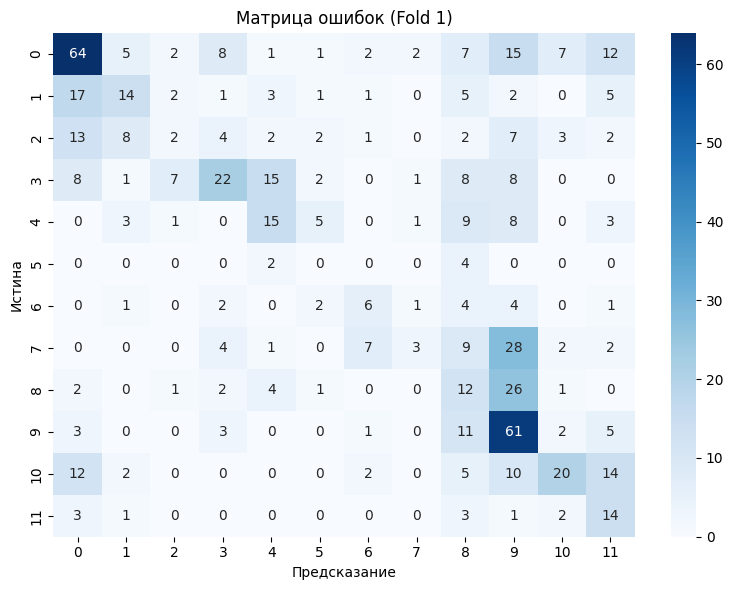

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9979
F1 macro (val):   0.3668
Gap (train-val):  0.6311

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.6754    0.6875    0.6814       112
           1     0.1905    0.2857    0.2286        14
           2     0.3158    0.2609    0.2857        46
           3     0.4098    0.3247    0.3623        77
           4     0.4556    0.6029    0.5190        68
           5     0.4000    0.0444    0.0800        45
           6     0.2632    0.1852    0.2174        27
           7     0.1935    0.1935    0.1935        31
           8     0.4725    0.5059    0.4886        85
           9     0.5116    0.5946    0.5500       111
          10     0.2162    0.3636    0.2712        22
          11     0.5000    0.5500    0.5238        20

    accuracy                    

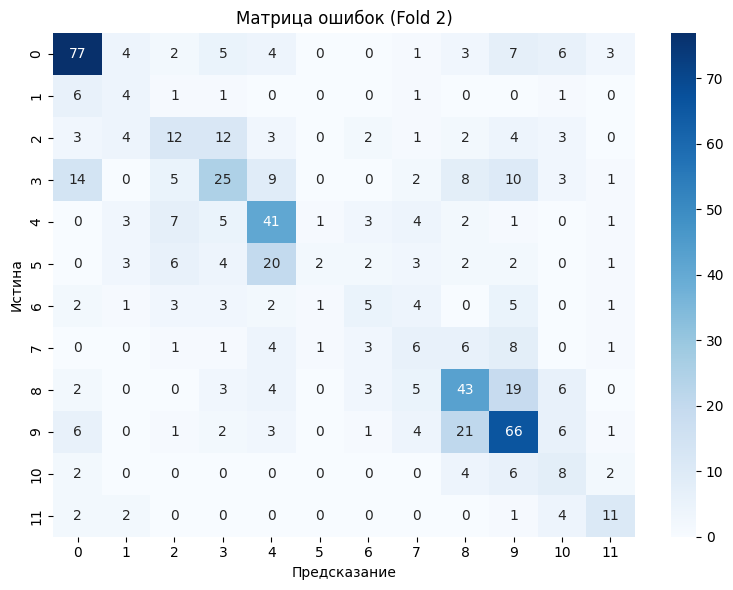

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9989
F1 macro (val):   0.3706
Gap (train-val):  0.6283

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.7565    0.6960    0.7250       125
           1     0.6875    0.3056    0.4231        36
           2     0.4643    0.4062    0.4333        32
           3     0.3077    0.4000    0.3478        30
           4     0.3556    0.4444    0.3951        36
           5     0.1000    0.0278    0.0435        36
           6     0.1176    0.0606    0.0800        33
           7     0.2308    0.0750    0.1132        40
           8     0.4719    0.4773    0.4746        88
           9     0.3562    0.6667    0.4643        78
          10     0.5682    0.5556    0.5618        45
          11     0.2973    0.5500    0.3860        20

    accuracy                    

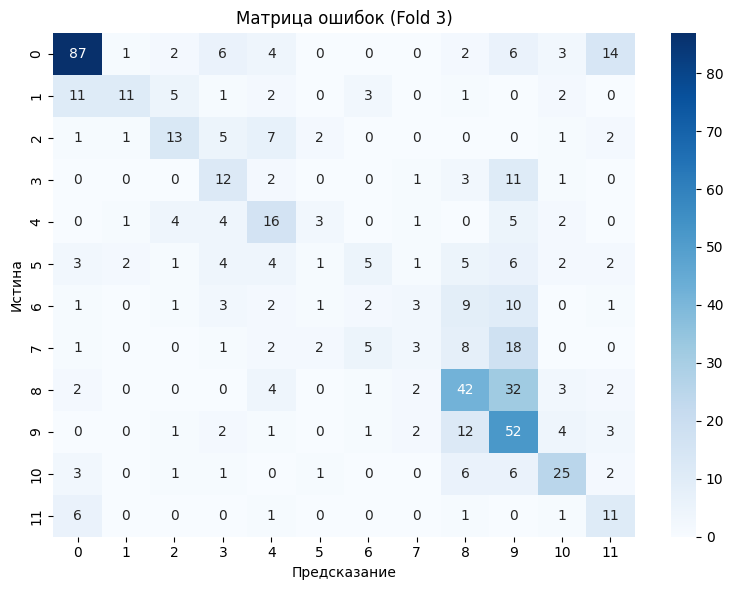

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9986
F1 macro (val):   0.3805
Gap (train-val):  0.6181

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.3846    0.8621    0.5319        58
           1     0.5000    0.1538    0.2353        39
           2     0.4286    0.3429    0.3810        35
           3     0.3191    0.2885    0.3030        52
           4     0.5714    0.5000    0.5333        56
           5     0.3333    0.1667    0.2222        24
           6     0.4375    0.2500    0.3182        28
           7     0.2000    0.0909    0.1250        44
           8     0.3544    0.4444    0.3944        63
           9     0.4706    0.5479    0.5063        73
          10     0.5862    0.6071    0.5965        56
          11     0.4815    0.3714    0.4194        35

    accuracy                    

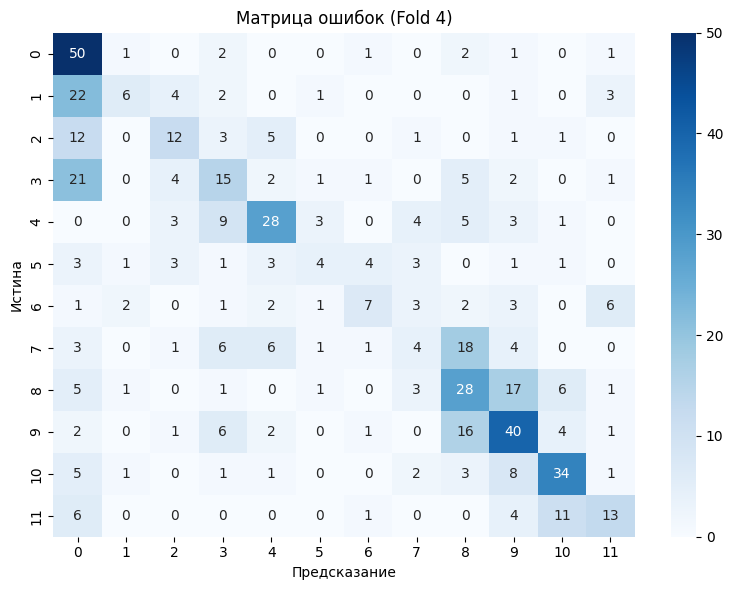

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9990
F1 macro (val):   0.2843
Gap (train-val):  0.7146

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.2059    0.7778    0.3256        27
           1     0.4000    0.2500    0.3077        16
           2     0.5000    0.2174    0.3030        23
           3     0.3500    0.3889    0.3684        36
           4     0.2979    0.5000    0.3733        28
           5     0.1579    0.1364    0.1463        22
           6     0.3333    0.1818    0.2353        22
           7     0.0312    0.0435    0.0364        23
           8     0.3889    0.5250    0.4468        80
           9     0.3485    0.3802    0.3636       121
          10     0.4571    0.2025    0.2807        79
          11     0.7857    0.1310    0.2245        84

    accuracy                    

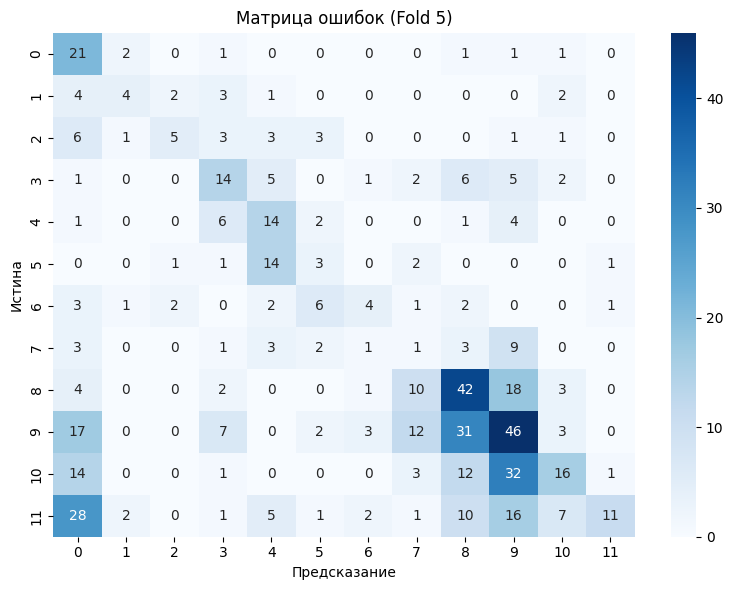

Результаты кросс-валидации
  Fold 1: F1_macro = 0.2838
  Fold 2: F1_macro = 0.3668
  Fold 3: F1_macro = 0.3706
  Fold 4: F1_macro = 0.3805
  Fold 5: F1_macro = 0.2843

  Средний F1 macro: 0.3372 ± 0.0436

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.5129    0.6674    0.5800       448
           1     0.4149    0.2500    0.3120       156
           2     0.3697    0.2418    0.2924       182
           3     0.3777    0.3296    0.3520       267
           4     0.4161    0.4893    0.4497       233
           5     0.1667    0.0752    0.1036       133
           6     0.2857    0.1832    0.2233       131
           7     0.1635    0.0876    0.1141       194
           8     0.3744    0.4575    0.4118       365
           9     0.4003    0.5650    0.4686       469
          10     0.4882    0.3858    0.4310       267
          11     0.3797    0.3279    0.3519       183

    accuracy                         0.4062      

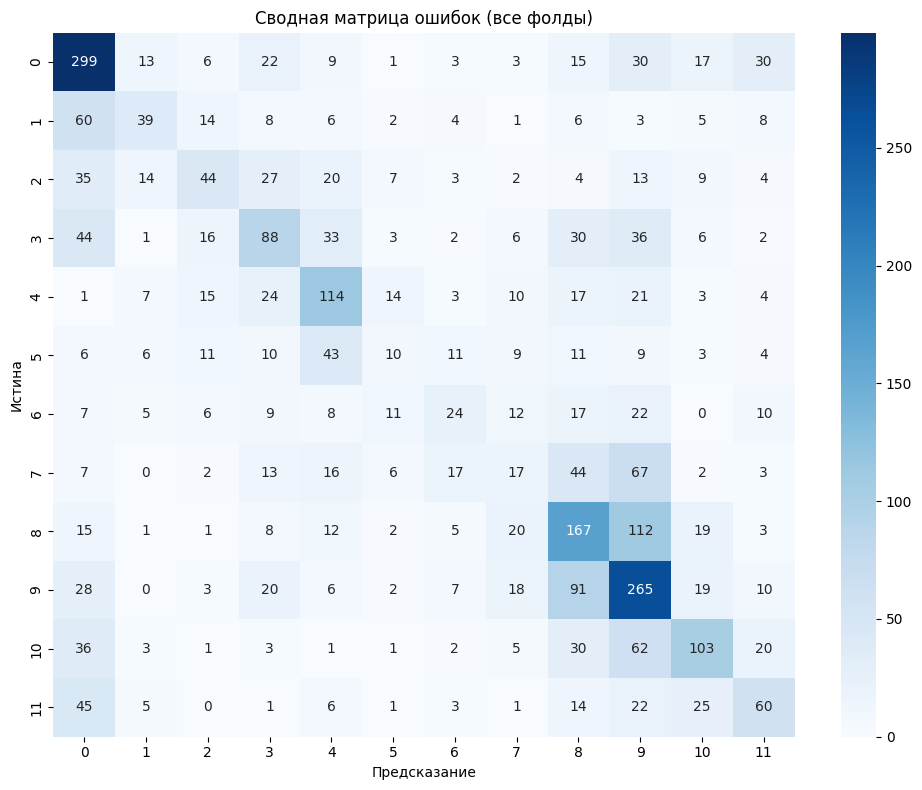

/tmp/ipykernel_405508/1167522210.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

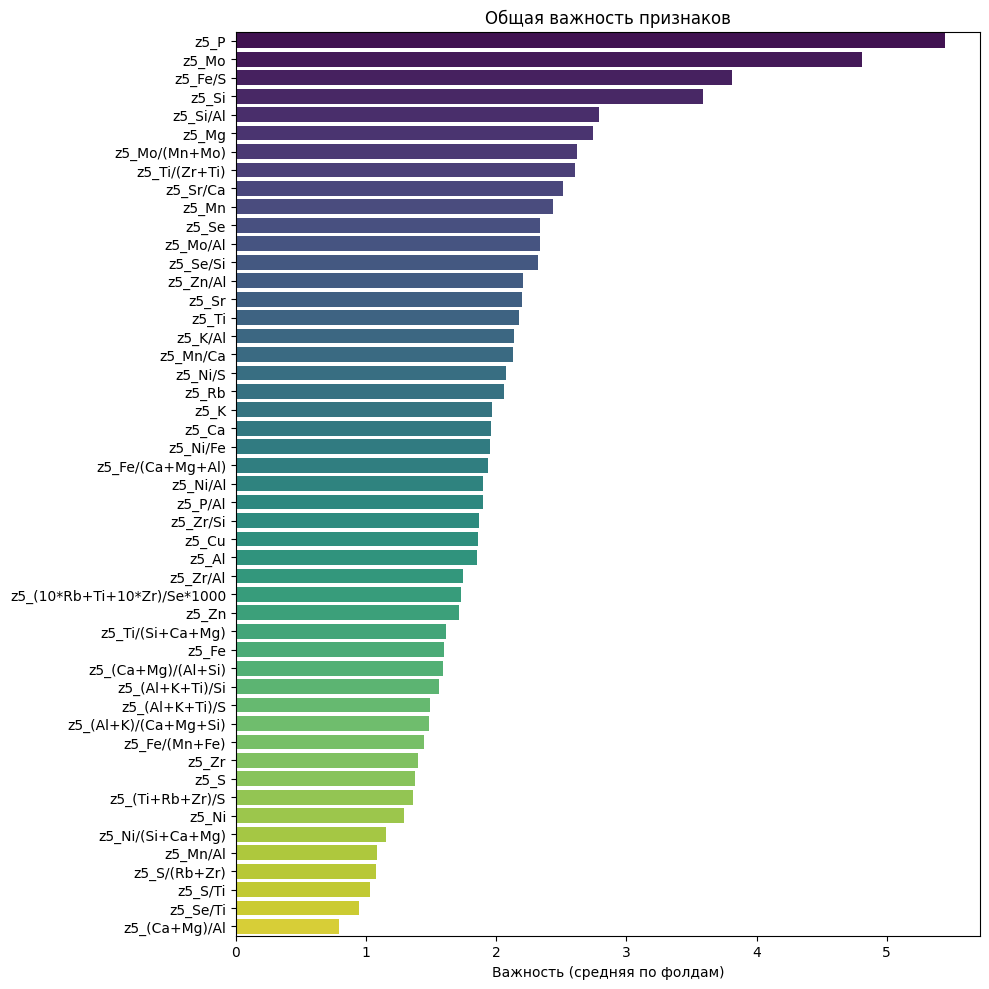

In [15]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Создание относительных градиентов rΔxi = xi / (xi-1 + epsilon)**

In [16]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

In [17]:
df = df.sort_values(['Well', 'Depth']).reset_index(drop=True)

rgrad_features = []
for col in features:
    rgrad_col = f'rΔ_{col}'
    prev = df.groupby('Well')[col].shift(1)
    epsilon = df[col].median() * 0.01
    df[rgrad_col] = df[col] / (prev + epsilon)
    rgrad_features.append(rgrad_col)

print(f"Добавлено в df: {len(rgrad_features)} признаков")
print(f"Всего колонок: {len(df.columns)}")


Добавлено в df: 49 признаков
Всего колонок: 201


In [19]:
print(df.columns.tolist())

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_

In [20]:
features = ['rΔ_Mg', 'rΔ_Al', 'rΔ_Si', 'rΔ_P', 'rΔ_S', 'rΔ_K', 'rΔ_Ca', 
            'rΔ_Ti', 'rΔ_Mn', 'rΔ_Fe', 'rΔ_Ni', 'rΔ_Cu', 'rΔ_Zn', 'rΔ_Se', 
            'rΔ_Rb', 'rΔ_Sr', 'rΔ_Zr', 'rΔ_Mo', 'rΔ_(Ca+Mg)/(Al+Si)', 
            'rΔ_Sr/Ca', 'rΔ_Mn/Ca', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Zr/Al', 
            'rΔ_Zr/Si', 'rΔ_K/Al', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Si/Al', 'rΔ_P/Al', 
            'rΔ_Ni/Fe', 'rΔ_Ni/(Si+Ca+Mg)', 'rΔ_S/(Rb+Zr)', 'rΔ_Mo/Al', 
            'rΔ_Mo/(Mn+Mo)', 'rΔ_Mn/Al', 'rΔ_Fe/S', 'rΔ_Ni/S', 'rΔ_Fe/(Ca+Mg+Al)', 
            'rΔ_Ti/(Si+Ca+Mg)', 'rΔ_Fe/(Mn+Fe)', 'rΔ_(Al+K+Ti)/Si', 'rΔ_(Al+K+Ti)/S', 
            'rΔ_(Ti+Rb+Zr)/S', 'rΔ_S/Ti', 'rΔ_Ni/Al', 'rΔ_Zn/Al', 'rΔ_Se/Si', 
            'rΔ_(Ca+Mg)/Al', 'rΔ_Se/Ti', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000']

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9949
F1 macro (val):   0.3444
Gap (train-val):  0.6504

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.6559    0.4841    0.5571       126
           1     0.5517    0.3137    0.4000        51
           2     0.2000    0.0652    0.0984        46
           3     0.4576    0.3750    0.4122        72
           4     0.2407    0.2889    0.2626        45
           5     0.0769    0.3333    0.1250         6
           6     0.2963    0.3810    0.3333        21
           7     0.4762    0.1786    0.2597        56
           8     0.2603    0.3878    0.3115        49
           9     0.4054    0.6977    0.5128        86
          10     0.5000    0.3692    0.4248        65
          11     0.3148    0.7083    0.4359        24

    accuracy                    

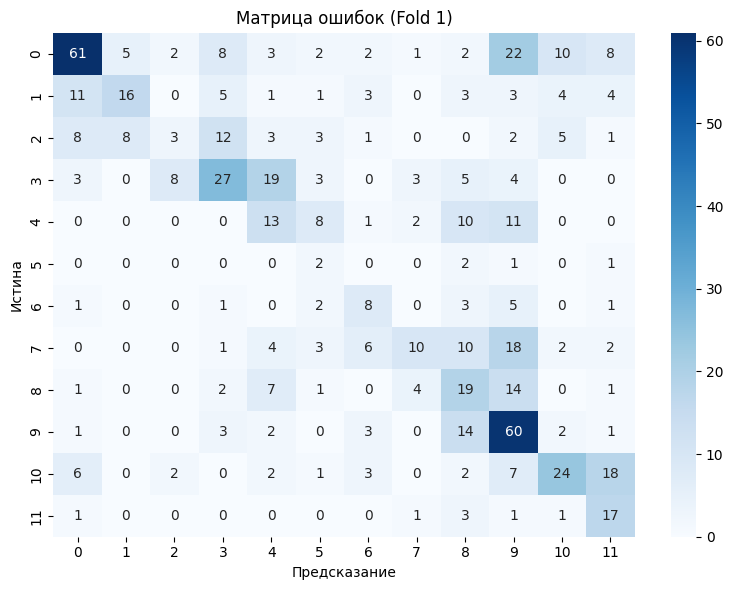

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9956
F1 macro (val):   0.4577
Gap (train-val):  0.5379

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.7870    0.7589    0.7727       112
           1     0.1707    0.5000    0.2545        14
           2     0.5152    0.3696    0.4304        46
           3     0.5441    0.4805    0.5103        77
           4     0.4677    0.4265    0.4462        68
           5     0.4545    0.1111    0.1786        45
           6     0.2609    0.2222    0.2400        27
           7     0.4800    0.3871    0.4286        31
           8     0.5125    0.4824    0.4970        85
           9     0.5755    0.7207    0.6400       111
          10     0.2558    0.5000    0.3385        22
          11     0.6800    0.8500    0.7556        20

    accuracy                    

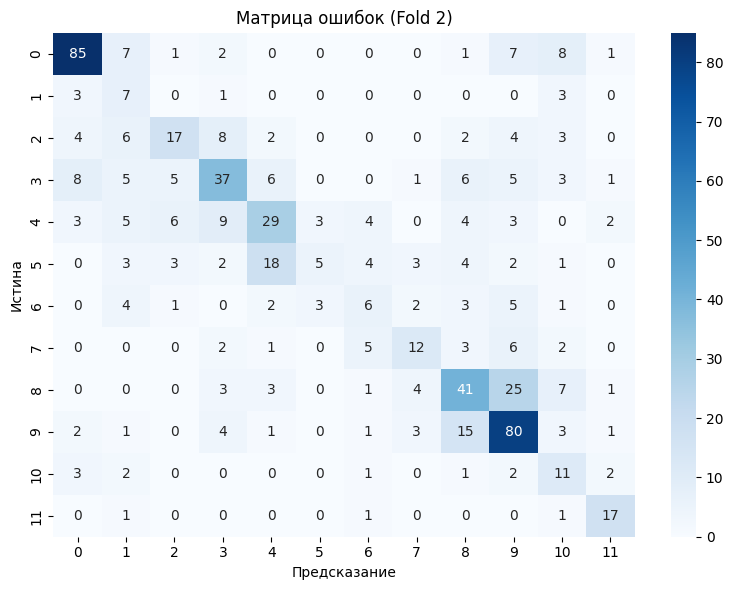

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9941
F1 macro (val):   0.4033
Gap (train-val):  0.5908

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.8534    0.7920    0.8216       125
           1     0.5000    0.2222    0.3077        36
           2     0.4167    0.3125    0.3571        32
           3     0.2391    0.3667    0.2895        30
           4     0.4186    0.5000    0.4557        36
           5     0.0000    0.0000    0.0000        36
           6     0.1000    0.0606    0.0755        33
           7     0.3939    0.3250    0.3562        40
           8     0.4725    0.4886    0.4804        88
           9     0.4273    0.6026    0.5000        78
          10     0.5536    0.6889    0.6139        45
          11     0.4571    0.8000    0.5818        20

    accuracy                    

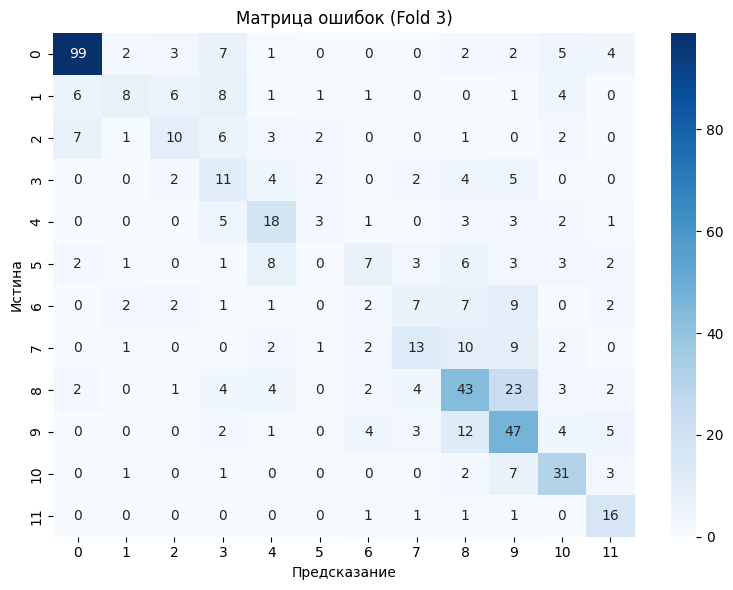

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9914
F1 macro (val):   0.4121
Gap (train-val):  0.5793

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.5495    0.8621    0.6711        58
           1     0.4348    0.2564    0.3226        39
           2     0.5000    0.4571    0.4776        35
           3     0.4792    0.4423    0.4600        52
           4     0.4222    0.3393    0.3762        56
           5     0.0769    0.0417    0.0541        24
           6     0.3793    0.3929    0.3860        28
           7     0.3500    0.1591    0.2188        44
           8     0.2615    0.2698    0.2656        63
           9     0.4811    0.6986    0.5698        73
          10     0.5522    0.6607    0.6016        56
          11     0.6667    0.4571    0.5424        35

    accuracy                    

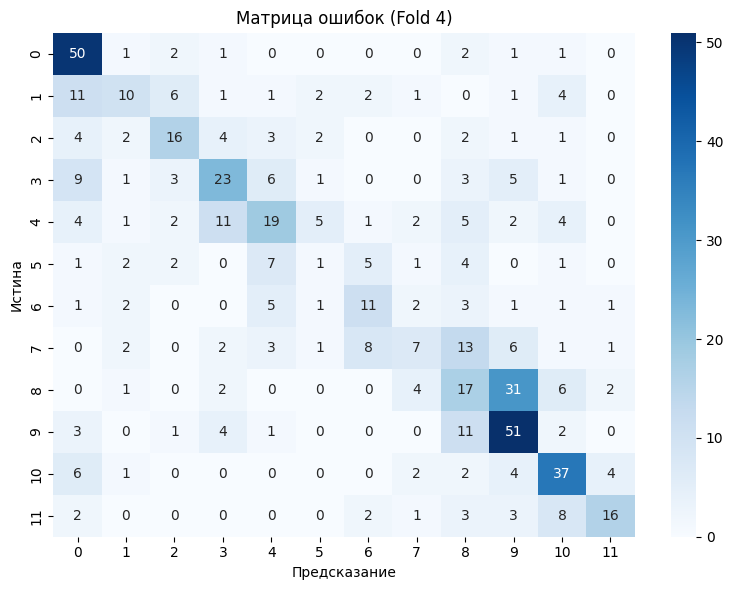

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9927
F1 macro (val):   0.2597
Gap (train-val):  0.7330

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.1729    0.8519    0.2875        27
           1     0.1111    0.0625    0.0800        16
           2     0.5000    0.3043    0.3784        23
           3     0.3333    0.3333    0.3333        36
           4     0.2368    0.3214    0.2727        28
           5     0.0667    0.0455    0.0541        22
           6     0.2500    0.1818    0.2105        22
           7     0.1429    0.0870    0.1081        23
           8     0.3673    0.4500    0.4045        80
           9     0.3672    0.3884    0.3775       121
          10     0.5400    0.3418    0.4186        79
          11     0.9000    0.1071    0.1915        84

    accuracy                    

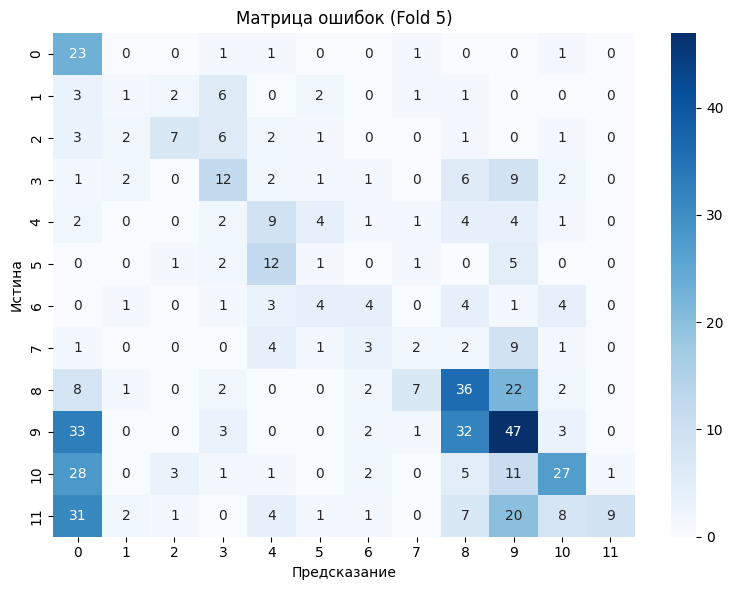

Результаты кросс-валидации
  Fold 1: F1_macro = 0.3444
  Fold 2: F1_macro = 0.4577
  Fold 3: F1_macro = 0.4033
  Fold 4: F1_macro = 0.4121
  Fold 5: F1_macro = 0.2597

  Средний F1 macro: 0.3755 ± 0.0682

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.5878    0.7098    0.6431       448
           1     0.3559    0.2692    0.3066       156
           2     0.4492    0.2912    0.3533       182
           3     0.4280    0.4120    0.4198       267
           4     0.3636    0.3777    0.3705       233
           5     0.1216    0.0677    0.0870       133
           6     0.2696    0.2366    0.2520       131
           7     0.3894    0.2268    0.2866       194
           8     0.3833    0.4274    0.4041       365
           9     0.4517    0.6077    0.5182       469
          10     0.4924    0.4869    0.4896       267
          11     0.5068    0.4098    0.4532       183

    accuracy                         0.4429      

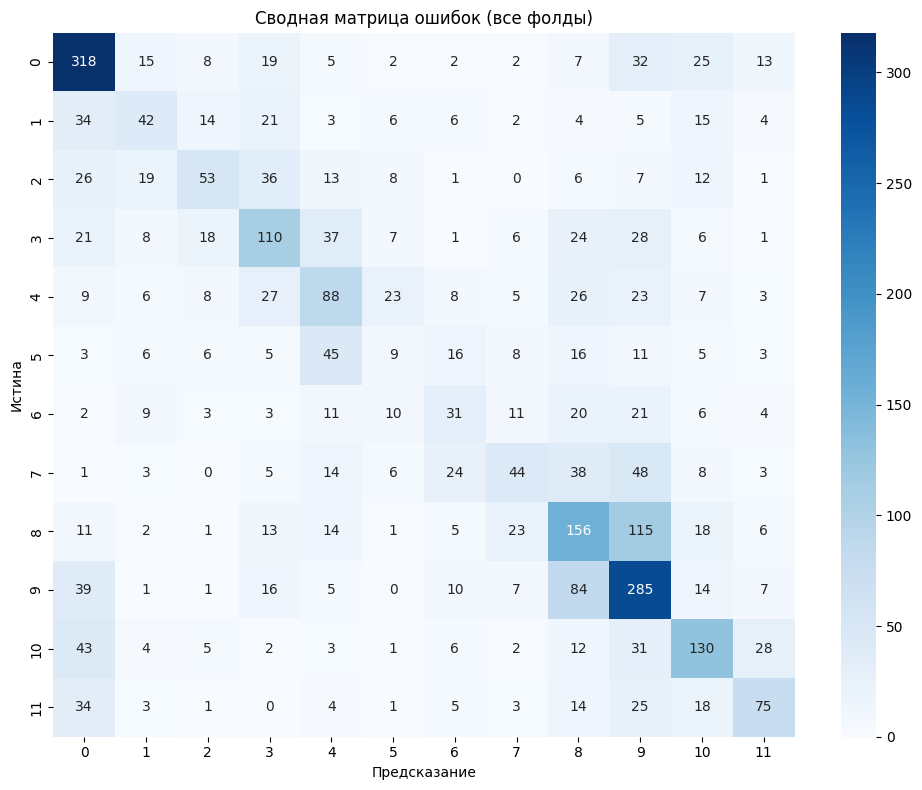

/tmp/ipykernel_405508/1167522210.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

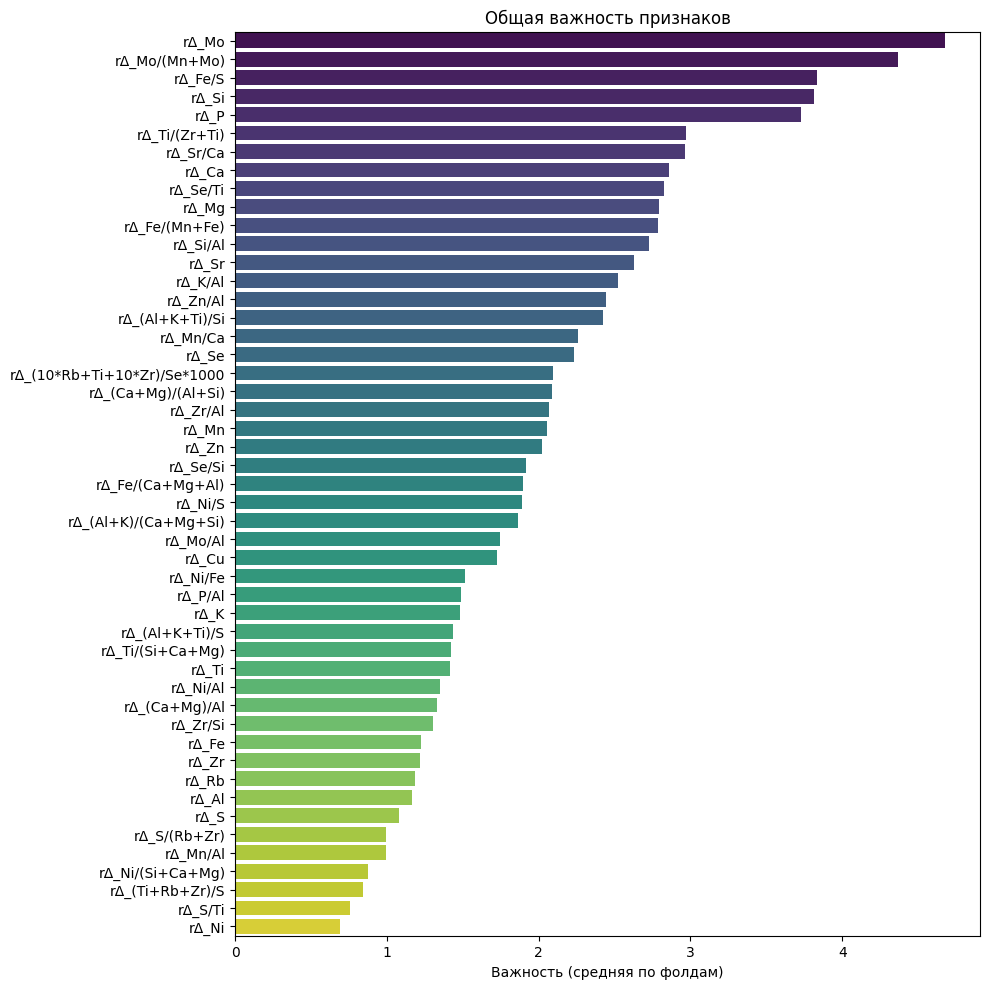

In [21]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

In [22]:
features = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 
            'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 
            'Mo', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 
            'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 
            'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 
            'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', 
            '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 
            'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 
            'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 
            'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 
            'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 
            'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 
            'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 
            'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Fe/(Mn+Fe)', 'dΔ_(Al+K+Ti)/Si', 
            'dΔ_(Al+K+Ti)/S', 'dΔ_(Ti+Rb+Zr)/S', 'dΔ_S/Ti', 'dΔ_Ni/Al', 'dΔ_Zn/Al', 'dΔ_Se/Si', 
            'dΔ_(Ca+Mg)/Al', 'dΔ_Se/Ti', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'z5_Mg', 'z5_Al', 'z5_Si', 
            'z5_P', 'z5_S', 'z5_K', 'z5_Ca', 'z5_Ti', 'z5_Mn', 'z5_Fe', 'z5_Ni', 'z5_Cu', 'z5_Zn', 
            'z5_Se', 'z5_Rb', 'z5_Sr', 'z5_Zr', 'z5_Mo', 'z5_(Ca+Mg)/(Al+Si)', 'z5_Sr/Ca', 'z5_Mn/Ca', 
            'z5_(Al+K)/(Ca+Mg+Si)', 'z5_Zr/Al', 'z5_Zr/Si', 'z5_K/Al', 'z5_Ti/(Zr+Ti)', 'z5_Si/Al', 
            'z5_P/Al', 'z5_Ni/Fe', 'z5_Ni/(Si+Ca+Mg)', 'z5_S/(Rb+Zr)', 'z5_Mo/Al', 'z5_Mo/(Mn+Mo)', 
            'z5_Mn/Al', 'z5_Fe/S', 'z5_Ni/S', 'z5_Fe/(Ca+Mg+Al)', 'z5_Ti/(Si+Ca+Mg)', 'z5_Fe/(Mn+Fe)', 
            'z5_(Al+K+Ti)/Si', 'z5_(Al+K+Ti)/S', 'z5_(Ti+Rb+Zr)/S', 'z5_S/Ti', 'z5_Ni/Al', 'z5_Zn/Al', 'z5_Se/Si', 
            'z5_(Ca+Mg)/Al', 'z5_Se/Ti', 'z5_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_Mg', 'rΔ_Al', 'rΔ_Si', 'rΔ_P', 'rΔ_S', 
            'rΔ_K', 'rΔ_Ca', 'rΔ_Ti', 'rΔ_Mn', 'rΔ_Fe', 'rΔ_Ni', 'rΔ_Cu', 'rΔ_Zn', 'rΔ_Se', 'rΔ_Rb', 'rΔ_Sr', 
            'rΔ_Zr', 'rΔ_Mo', 'rΔ_(Ca+Mg)/(Al+Si)', 'rΔ_Sr/Ca', 'rΔ_Mn/Ca', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Zr/Al', 
            'rΔ_Zr/Si', 'rΔ_K/Al', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Si/Al', 'rΔ_P/Al', 'rΔ_Ni/Fe', 'rΔ_Ni/(Si+Ca+Mg)', 
            'rΔ_S/(Rb+Zr)', 'rΔ_Mo/Al', 'rΔ_Mo/(Mn+Mo)', 'rΔ_Mn/Al', 'rΔ_Fe/S', 'rΔ_Ni/S', 'rΔ_Fe/(Ca+Mg+Al)', 
            'rΔ_Ti/(Si+Ca+Mg)', 'rΔ_Fe/(Mn+Fe)', 'rΔ_(Al+K+Ti)/Si', 'rΔ_(Al+K+Ti)/S', 'rΔ_(Ti+Rb+Zr)/S', 
            'rΔ_S/Ti', 'rΔ_Ni/Al', 'rΔ_Zn/Al', 'rΔ_Se/Si', 'rΔ_(Ca+Mg)/Al', 'rΔ_Se/Ti', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000']

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9996
F1 macro (val):   0.5884
Gap (train-val):  0.4112

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9062    0.6905    0.7838       126
           1     0.6500    0.7647    0.7027        51
           2     0.4333    0.5652    0.4906        46
           3     0.5532    0.7222    0.6265        72
           4     0.5088    0.6444    0.5686        45
           5     0.3333    0.6667    0.4444         6
           6     0.3611    0.6190    0.4561        21
           7     0.6316    0.2143    0.3200        56
           8     0.4151    0.4490    0.4314        49
           9     0.7419    0.8023    0.7709        86
          10     0.9000    0.6923    0.7826        65
          11     0.8235    0.5833    0.6829        24

    accuracy                    

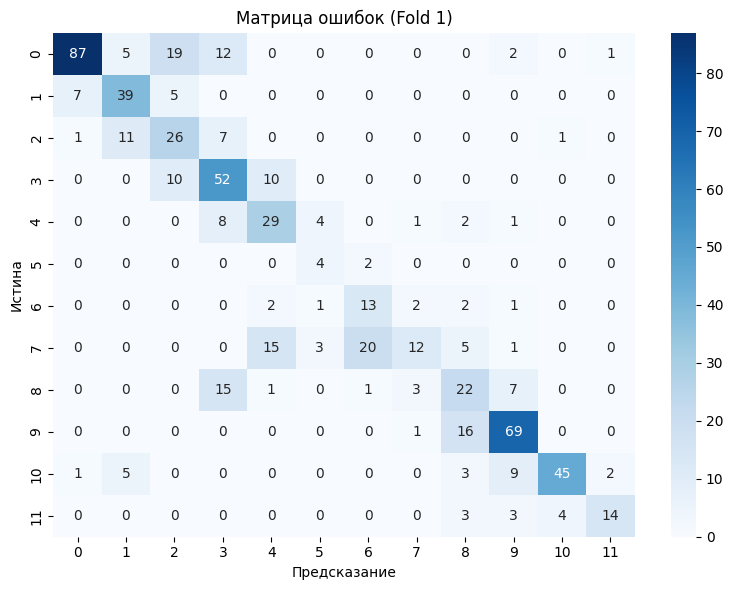

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9991
F1 macro (val):   0.6996
Gap (train-val):  0.2995

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9604    0.8661    0.9108       112
           1     0.4444    0.8571    0.5854        14
           2     0.6250    0.6522    0.6383        46
           3     0.8889    0.8312    0.8591        77
           4     0.6176    0.9265    0.7412        68
           5     0.5000    0.1778    0.2623        45
           6     0.4737    0.3333    0.3913        27
           7     0.5429    0.6129    0.5758        31
           8     0.7500    0.8118    0.7797        85
           9     0.8952    0.8468    0.8704       111
          10     0.8947    0.7727    0.8293        22
          11     0.9091    1.0000    0.9524        20

    accuracy                    

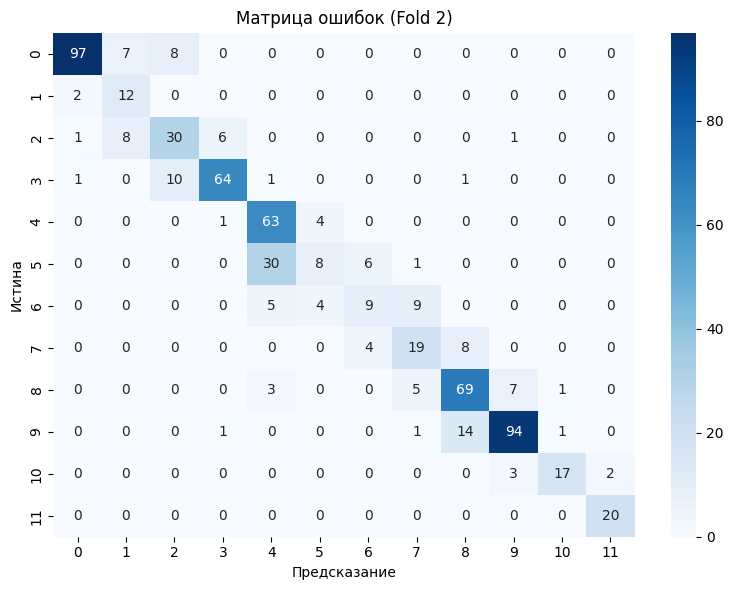

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9980
F1 macro (val):   0.6522
Gap (train-val):  0.3458

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9606    0.9760    0.9683       125
           1     0.8571    0.6667    0.7500        36
           2     0.7241    0.6562    0.6885        32
           3     0.7353    0.8333    0.7812        30
           4     0.5294    0.5000    0.5143        36
           5     0.3333    0.1667    0.2222        36
           6     0.2273    0.1515    0.1818        33
           7     0.3636    0.3000    0.3288        40
           8     0.6455    0.8068    0.7172        88
           9     0.7684    0.9359    0.8439        78
          10     0.8750    0.9333    0.9032        45
          11     0.9048    0.9500    0.9268        20

    accuracy                    

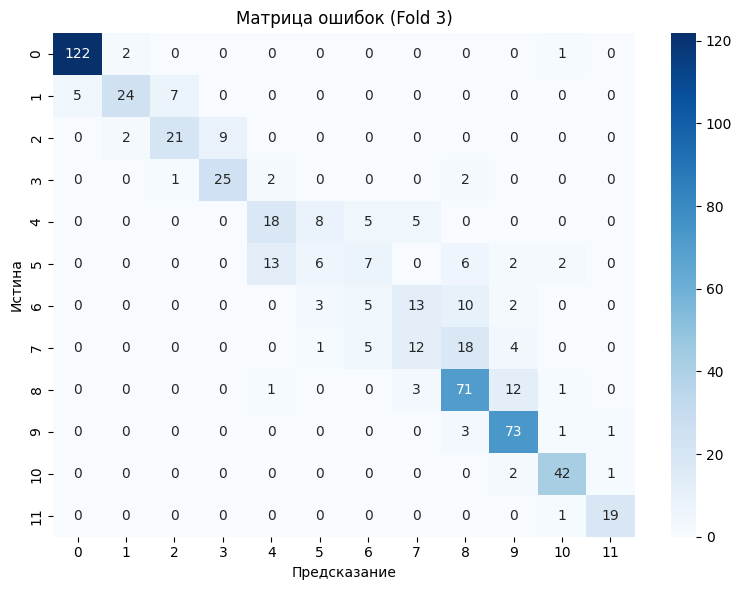

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9991
F1 macro (val):   0.6635
Gap (train-val):  0.3357

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9206    1.0000    0.9587        58
           1     1.0000    0.4103    0.5818        39
           2     0.4286    0.6857    0.5275        35
           3     0.7358    0.7500    0.7429        52
           4     0.8889    0.7143    0.7921        56
           5     0.5652    0.5417    0.5532        24
           6     0.5135    0.6786    0.5846        28
           7     0.4615    0.1364    0.2105        44
           8     0.4844    0.4921    0.4882        63
           9     0.6667    0.9315    0.7771        73
          10     0.8308    0.9643    0.8926        56
          11     1.0000    0.7429    0.8525        35

    accuracy                    

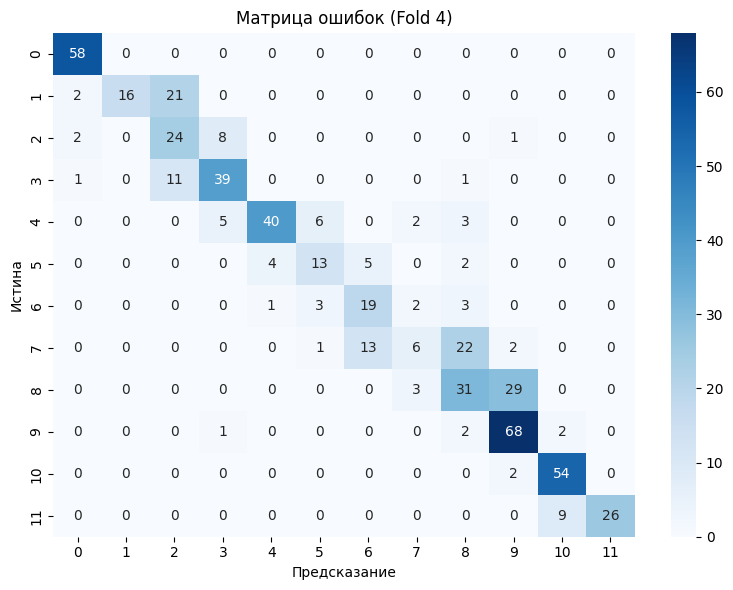

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9979
F1 macro (val):   0.5754
Gap (train-val):  0.4225

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.6000    1.0000    0.7500        27
           1     0.6250    0.3125    0.4167        16
           2     0.5714    0.5217    0.5455        23
           3     0.7619    0.8889    0.8205        36
           4     0.5000    0.8214    0.6216        28
           5     0.2727    0.1364    0.1818        22
           6     0.6500    0.5909    0.6190        22
           7     0.2500    0.3043    0.2745        23
           8     0.5625    0.5625    0.5625        80
           9     0.7188    0.7603    0.7390       121
          10     0.6703    0.7722    0.7176        79
          11     1.0000    0.4881    0.6560        84

    accuracy                    

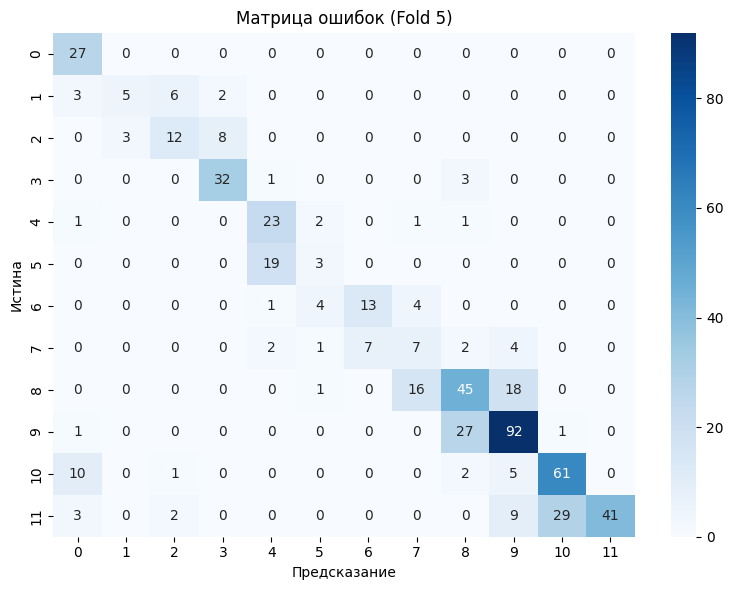

Результаты кросс-валидации
  Fold 1: F1_macro = 0.5884
  Fold 2: F1_macro = 0.6996
  Fold 3: F1_macro = 0.6522
  Fold 4: F1_macro = 0.6635
  Fold 5: F1_macro = 0.5754

  Средний F1 macro: 0.6358 ± 0.0469

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9051    0.8728    0.8886       448
           1     0.6906    0.6154    0.6508       156
           2     0.5280    0.6209    0.5707       182
           3     0.7186    0.7940    0.7544       267
           4     0.6092    0.7425    0.6692       233
           5     0.4250    0.2556    0.3192       133
           6     0.4403    0.4504    0.4453       131
           7     0.4375    0.2887    0.3478       194
           8     0.5965    0.6521    0.6230       365
           9     0.7572    0.8443    0.7984       469
          10     0.8022    0.8202    0.8111       267
          11     0.9449    0.6557    0.7742       183

    accuracy                         0.6958      

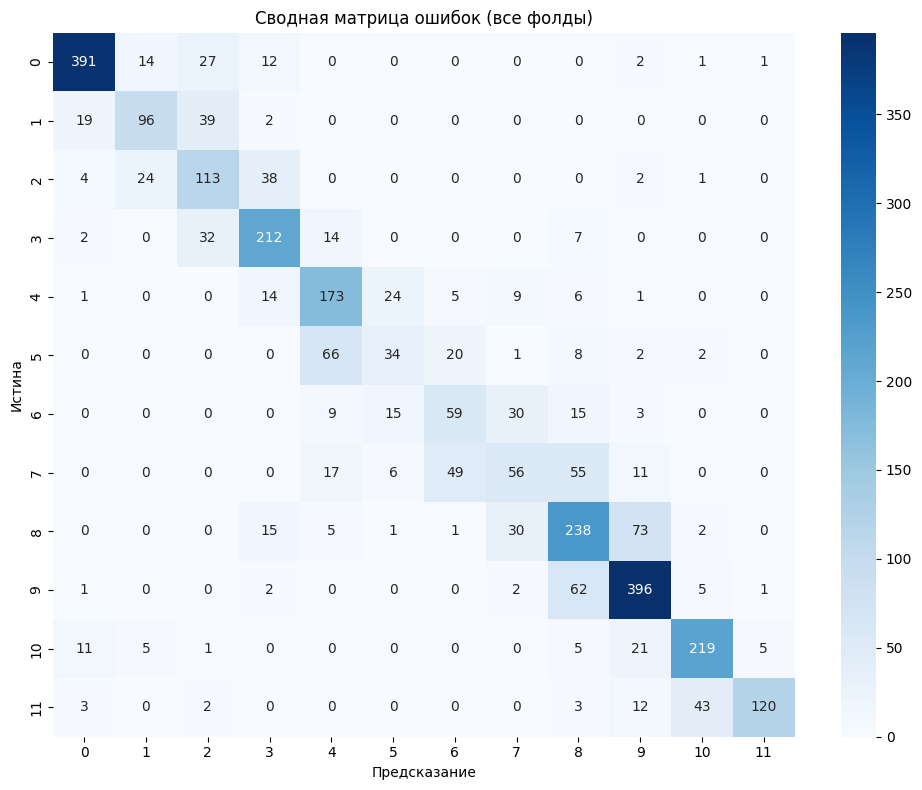

/tmp/ipykernel_405508/1167522210.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

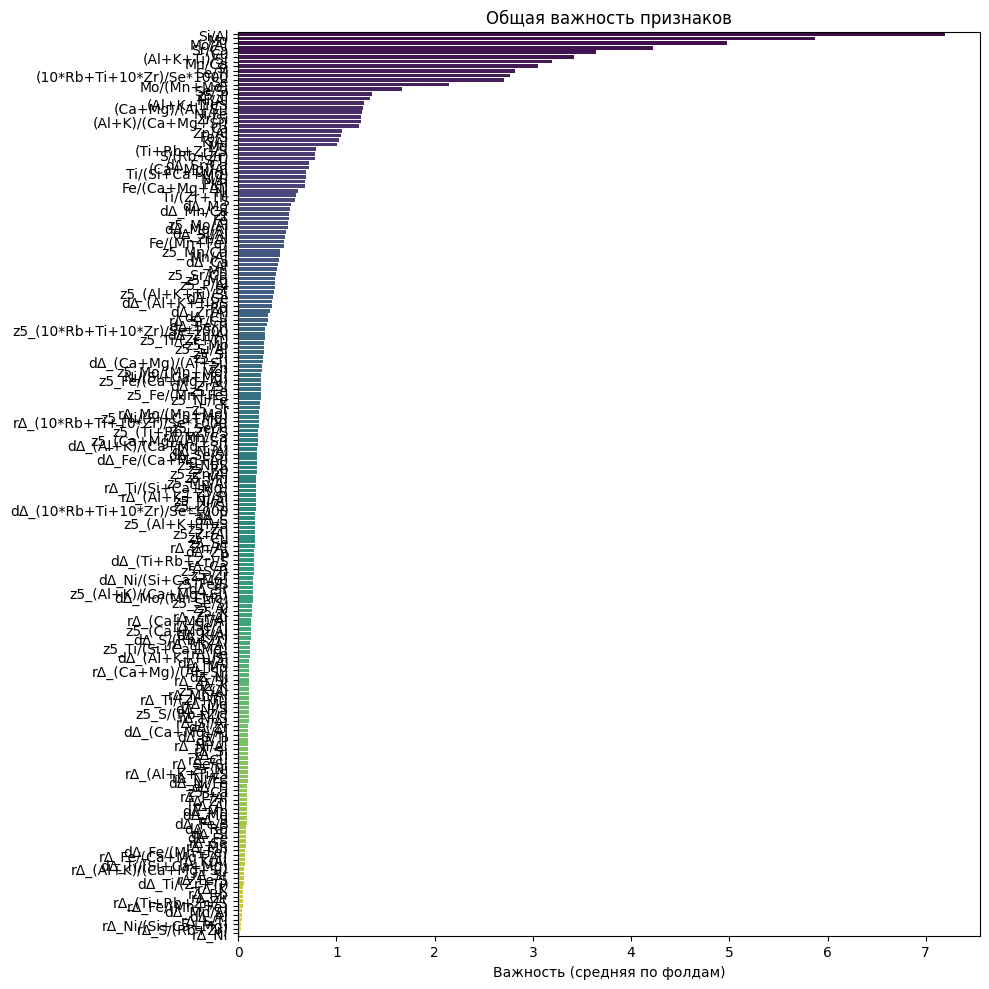

In [23]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()